# Exploration du projet 1 - Avions

Ce notebook sert à explorer les données et à tester les premières analyses.

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torchvision
from PIL import Image

In [9]:
from pathlib import Path

import torch
import torchvision

print("torch       :", torch.__version__)
print("torchvision :", torchvision.__version__)
print("MPS dispo   :", torch.backends.mps.is_available())

# Le notebook tourne depuis projet1_avions/notebooks/ : on remonte d'un niveau
DATA_DIR = Path("..") / "data"
print("DATA_DIR    :", DATA_DIR.resolve())
print("Existe      :", DATA_DIR.exists())

torch       : 2.14.1
torchvision : 0.29.1
MPS dispo   : True
DATA_DIR    : /Users/mnl-macpro/Projets/Cours DL images/projet1_avions/data
Existe      : True


In [10]:
from torchvision.datasets import FGVCAircraft

# Téléchargement (à lancer une seule fois, puis passer download=False)
train_set = FGVCAircraft(
    root=DATA_DIR,       # dossier où ranger le dataset
    split="train",       # quel sous-ensemble charger
    download=True,       # télécharger l'archive si elle n'est pas déjà là
)

print("Nombre d'images (train) :", len(train_set))
print("Nombre de classes        :", len(train_set.classes))
print("Exemples de classes      :", train_set.classes[:5])

Nombre d'images (train) : 3334
Nombre de classes        : 100
Exemples de classes      : ['707-320', '727-200', '737-200', '737-300', '737-400']


In [11]:
import pandas as pd

AIRCRAFT_DIR = DATA_DIR / "fgvc-aircraft-2013b" / "data"
LEVELS = ["manufacturer", "family", "variant"]
SPLITS = ["train", "val", "test"]


def read_labels(level, split):
    """Lit images_<level>_<split>.txt et renvoie une Series : id_image -> classe."""
    path = AIRCRAFT_DIR / f"images_{level}_{split}.txt"
    rows = [line.split(" ", 1) for line in path.read_text().splitlines() if line.strip()]
    return pd.DataFrame(rows, columns=["image_id", level]).set_index("image_id")[level]


frames = []
for split in SPLITS:
    # Les 3 niveaux côte à côte, alignés sur l'identifiant d'image
    df_split = pd.concat([read_labels(level, split) for level in LEVELS], axis=1)
    df_split["split"] = split
    frames.append(df_split)

df = pd.concat(frames).reset_index()

print("Taille du tableau :", df.shape)
print("Valeurs manquantes :", df.isna().sum().sum())
df.head()

Taille du tableau : (10000, 5)
Valeurs manquantes : 0


,image_id,manufacturer,family,variant,split
0,1025794,Boeing,Boeing 707,707-320,train
1,1340192,Boeing,Boeing 707,707-320,train
2,0056978,Boeing,Boeing 707,707-320,train
3,0698580,Boeing,Boeing 707,707-320,train
4,0450014,Boeing,Boeing 707,707-320,train


In [12]:
print("Images par split :")
print(df["split"].value_counts(), "\n")

print("Nombre de classes par niveau :")
print(df[LEVELS].nunique())

Images par split :
split
train    3334
val      3333
test     3333
Name: count, dtype: int64 

Nombre de classes par niveau :
manufacturer     30
family           70
variant         100
dtype: int64


In [13]:
# Chaque variante doit appartenir à une seule famille, et chaque famille à un seul constructeur
fam_par_variante = df.groupby("variant")["family"].nunique()
cons_par_famille = df.groupby("family")["manufacturer"].nunique()

print("Max de familles par variante     :", fam_par_variante.max())
print("Max de constructeurs par famille :", cons_par_famille.max())

# Taille des sous-arbres : combien de variantes par constructeur et par famille
print("\nVariantes par constructeur (top 5) :")
print(df.groupby("manufacturer")["variant"].nunique().sort_values(ascending=False).head())
print("\nVariantes par famille (top 3) :")
print(df.groupby("family")["variant"].nunique().sort_values(ascending=False).head(3))

Max de familles par variante     : 1
Max de constructeurs par famille : 1

Variantes par constructeur (top 5) :
manufacturer
Boeing               22
Airbus               13
McDonnell Douglas     7
Embraer               7
de Havilland          5
Name: variant, dtype: int64

Variantes par famille (top 3) :
family
Boeing 737    8
A320          4
A340          4
Name: variant, dtype: int64


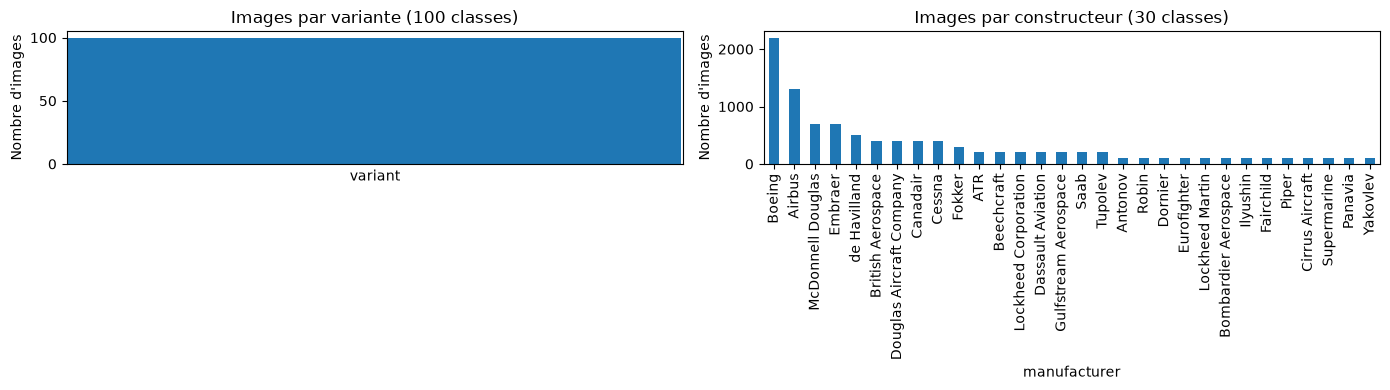

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Images par variante (niveau le plus fin)
df["variant"].value_counts().plot(kind="bar", ax=axes[0], width=1.0)
axes[0].set_title("Images par variante (100 classes)")
axes[0].set_xticks([])                      # 100 noms illisibles : on les masque
axes[0].set_ylabel("Nombre d'images")

# Images par constructeur (niveau le plus grossier)
df["manufacturer"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("Images par constructeur (30 classes)")
axes[1].set_ylabel("Nombre d'images")

plt.tight_layout()
plt.show()

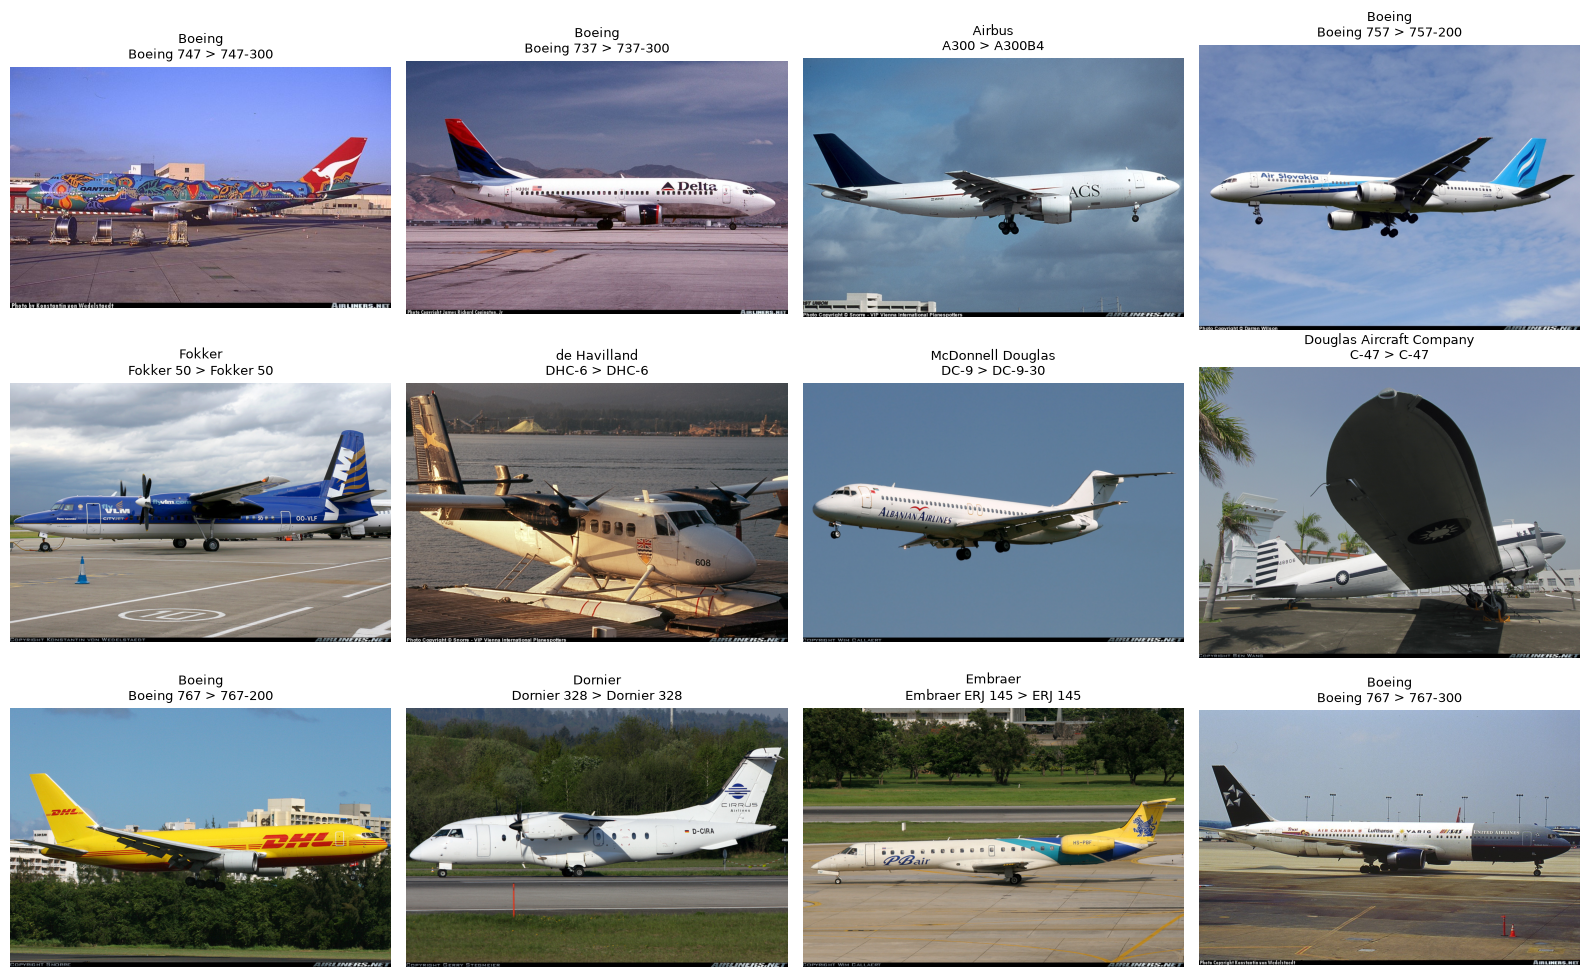

In [15]:
samples = df[df["split"] == "train"].sample(12, random_state=0)

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, row in zip(axes.flat, samples.itertuples()):
    img = Image.open(AIRCRAFT_DIR / "images" / f"{row.image_id}.jpg")
    ax.imshow(img)
    ax.set_title(f"{row.manufacturer}\n{row.family} > {row.variant}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

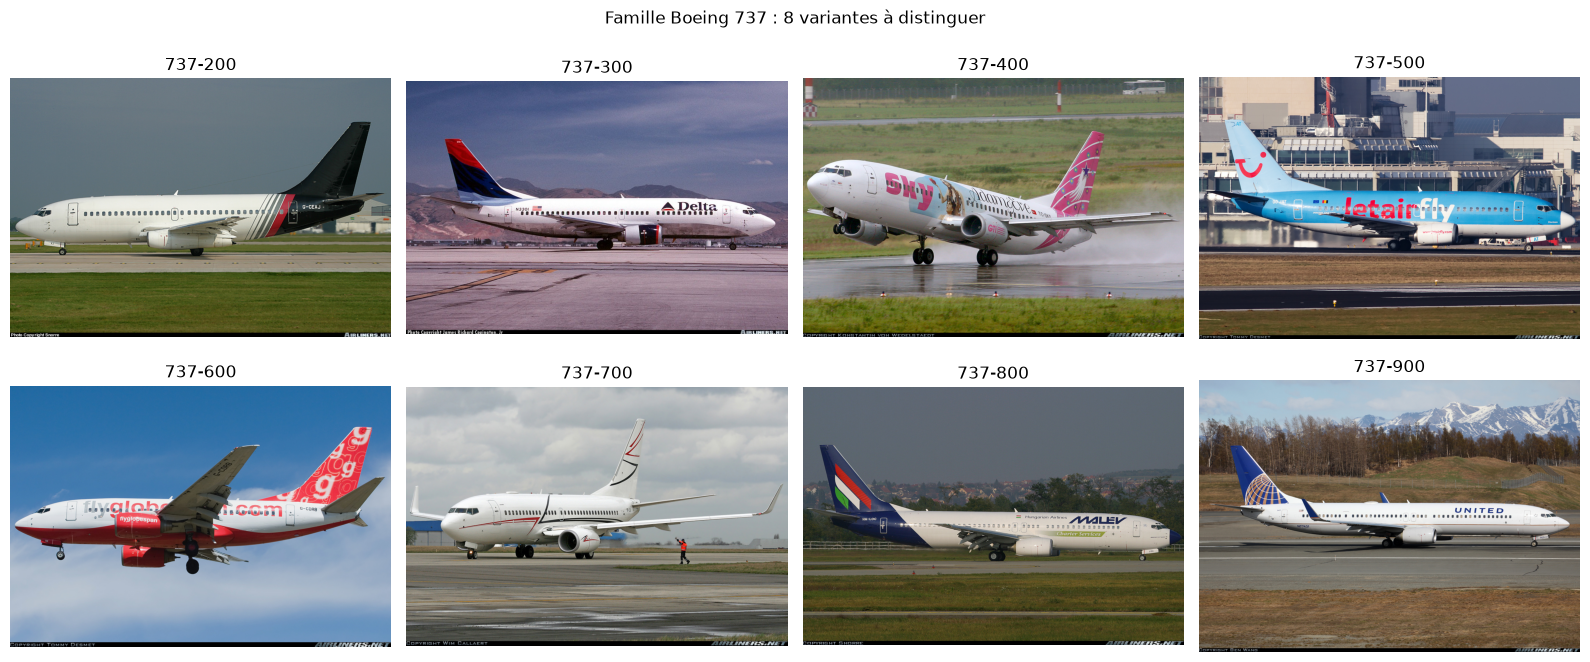

In [16]:
# Une image par variante de la famille Boeing 737 (8 variantes)
b737 = df[df["family"] == "Boeing 737"].groupby("variant").sample(1, random_state=0)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, row in zip(axes.flat, b737.itertuples()):
    ax.imshow(Image.open(AIRCRAFT_DIR / "images" / f"{row.image_id}.jpg"))
    ax.set_title(row.variant)
    ax.axis("off")

plt.suptitle("Famille Boeing 737 : 8 variantes à distinguer")
plt.tight_layout()
plt.show()

     largeur  hauteur
min    800.0    491.0
50%   1024.0    698.5
max   1600.0   1118.0


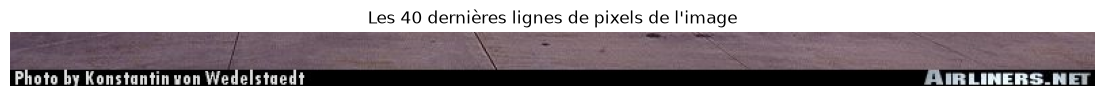

In [17]:
# Tailles d'images : sont-elles toutes identiques ?
sizes = [Image.open(AIRCRAFT_DIR / "images" / f"{i}.jpg").size for i in df["image_id"].sample(300, random_state=0)]
sizes = pd.DataFrame(sizes, columns=["largeur", "hauteur"])
print(sizes.describe().loc[["min", "50%", "max"]])

# Zoom sur le bas d'une image : le bandeau de copyright
img = Image.open(AIRCRAFT_DIR / "images" / f"{samples.iloc[0].image_id}.jpg")
w, h = img.size
bas = img.crop((0, h - 40, w, h))          # (gauche, haut, droite, bas)

plt.figure(figsize=(14, 2))
plt.imshow(bas)
plt.title("Les 40 dernières lignes de pixels de l'image")
plt.axis("off")
plt.show()